# 01 — CairoGo Dataset Overview

**Pack:** v17 | **Leader ID:** 20231067  
**Goal:** Phase 0.2 — Dataset inspection. No cleaning or modelling here.

> ⚠️ Read `docs/DATA_DICTIONARY.md` and `docs/PROJECT_DECISIONS.md` before editing this notebook.

In [99]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)

PACK = Path("../data/raw/cairogo_pack").resolve()

FOUNDATION = 'data/raw/foundation'
RANDOM_STATE = 42
print('Libraries loaded ✓')



Libraries loaded ✓


## 1. Load All Tables

In [100]:
trips    = pd.read_csv(f'{PACK}/trips.csv', parse_dates=['request_ts'])
customers = pd.read_csv(f'{PACK}/customers.csv', parse_dates=['signup_date'])
drivers  = pd.read_csv(f'{PACK}/drivers.csv', parse_dates=['join_date'])
zones    = pd.read_csv(f'{PACK}/zones.csv')
recent   = pd.read_csv(f'{PACK}/recent_labelled.csv', parse_dates=['request_ts'])
holdout  = pd.read_csv(f'{PACK}/holdout_inputs.csv', parse_dates=['request_ts'])

tables = {'trips': trips, 'customers': customers, 'drivers': drivers,
          'zones': zones, 'recent_labelled': recent, 'holdout_inputs': holdout}

for name, df in tables.items():
    print(f'{name:20s}: {df.shape[0]:6,} rows × {df.shape[1]:2} cols')

trips               : 27,226 rows × 18 cols
customers           :  6,000 rows ×  5 cols
drivers             :  1,500 rows ×  6 cols
zones               :     24 rows ×  5 cols
recent_labelled     :  3,630 rows × 18 cols
holdout_inputs      :  2,832 rows × 13 cols


## 2. trips.csv — Shape, Types & Sample

In [101]:
print('Shape:', trips.shape)
trips.head(3)

Shape: (27226, 18)


,trip_id,customer_id,driver_id,request_ts,pickup_zone,dropoff_zone,distance_km,surge_multiplier,est_fare,eta_estimate_min,weather,payment_method,service_level,request_failed,actual_trip_time_min,cancel_reason,support_ticket_flag,driver_arrival_min
0,100001,21924,5062,2026-05-01 00:01:46,Dokki,Badr City,17.220,1.100,107.400,6.400,NaN,card,economy,0,29.900,NaN,0,5.100
1,100002,20391,5681,2026-05-01 00:37:36,Dokki,Obour,12.740,1.100,114.900,7.300,rain,cash,comfort,0,28.900,NaN,0,7.000
2,100003,24083,5407,2026-05-01 00:40:12,Maadi,Obour,10.800,1.000,92.300,6.400,NaN,card,comfort,0,22.500,NaN,0,4.000


In [102]:
trips.dtypes

trip_id                          int64
customer_id                      int64
driver_id                        int64
request_ts              datetime64[us]
pickup_zone                        str
dropoff_zone                       str
distance_km                    float64
surge_multiplier               float64
est_fare                       float64
eta_estimate_min               float64
weather                            str
payment_method                     str
service_level                      str
request_failed                   int64
actual_trip_time_min           float64
cancel_reason                      str
support_ticket_flag              int64
driver_arrival_min             float64
dtype: object

## 3. Missing Values

In [103]:
missing = trips.isnull().sum()
missing_pct = (missing / len(trips) * 100).round(2)
miss_df = pd.DataFrame({'count': missing, 'pct': missing_pct})
miss_df = miss_df[miss_df['count'] > 0]
print('Columns with missing values:')
print(miss_df.to_string())
print('\n⚠️  actual_trip_time_min, cancel_reason, driver_arrival_min are missing ONLY for failed trips — this is expected (not a data quality issue).')

Columns with missing values:
                      count    pct
weather                1313  4.820
actual_trip_time_min   5666 20.810
cancel_reason         21560 79.190
driver_arrival_min     5666 20.810

⚠️  actual_trip_time_min, cancel_reason, driver_arrival_min are missing ONLY for failed trips — this is expected (not a data quality issue).


## 4. Target Variable — request_failed

Target distribution:
                count    pct
request_failed              
0               21560 79.200
1                5666 20.800


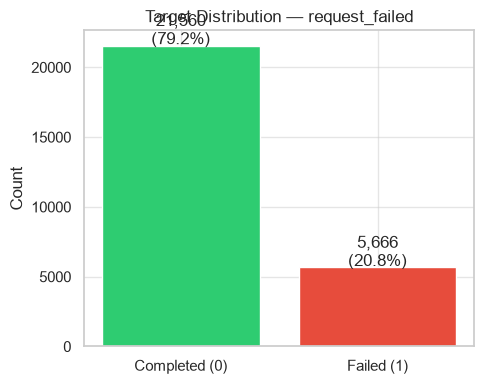


⚠️  Class imbalance: ~18% failed — keep this in mind for modelling (use stratified split, check precision/recall).


In [104]:
target_counts = trips['request_failed'].value_counts()
target_pct    = trips['request_failed'].value_counts(normalize=True) * 100

print('Target distribution:')
print(pd.DataFrame({'count': target_counts, 'pct': target_pct.round(1)}))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Completed (0)', 'Failed (1)'], target_counts.values,
       color=['#2ecc71', '#e74c3c'])
ax.set_title('Target Distribution — request_failed')
ax.set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 100, f'{v:,}\n({target_pct.values[i]:.1f}%)', ha='center')
plt.tight_layout()
plt.savefig('../reports/figures/target_distribution.png', dpi=150)
plt.show()
print('\n⚠️  Class imbalance: ~18% failed — keep this in mind for modelling (use stratified split, check precision/recall).')

## 5. Numerical Features — Summary Stats

In [105]:
# SAFE features only (at_request)
num_features = ['distance_km', 'surge_multiplier', 'est_fare', 'eta_estimate_min']
trips[num_features].describe().round(3)

,distance_km,surge_multiplier,est_fare,eta_estimate_min
count,27226.000,27226.000,27226.000,27226.000
mean,10.894,1.258,103.338,9.015
std,6.678,0.331,56.723,4.022
min,1.140,1.000,27.200,2.700
25%,5.500,1.000,65.400,5.800
50%,9.430,1.100,90.600,8.200
75%,14.620,1.400,124.300,11.475
max,60.000,2.600,718.000,29.400


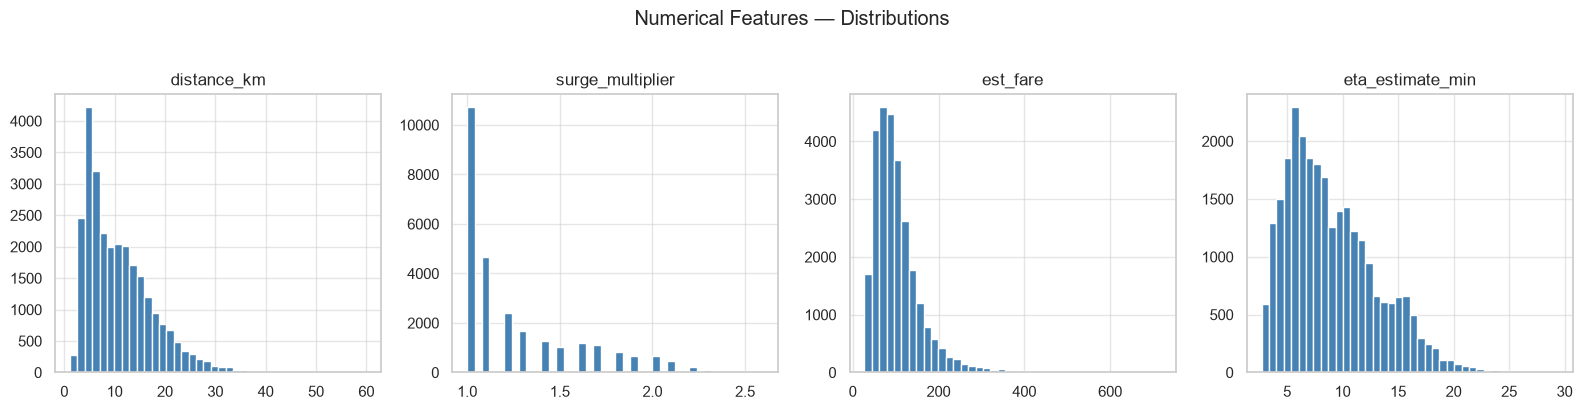

In [106]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_features):
    trips[col].hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
plt.suptitle('Numerical Features — Distributions', y=1.02)
plt.tight_layout()
plt.savefig('../reports/figures/num_distributions.png', dpi=150)
plt.show()

## 6. Categorical Features — Value Counts

In [107]:
cat_features = ['weather', 'payment_method', 'service_level']
for col in cat_features:
    print(f'\n{col}:')
    print(trips[col].value_counts(dropna=False).to_string())


weather:
weather
clear    22394
dust      1858
rain      1661
NaN       1313

payment_method:
payment_method
cash      14228
card      10126
wallet     2872

service_level:
service_level
economy    19150
comfort     5926
premium     2150


## 7. Failure Rate by Category

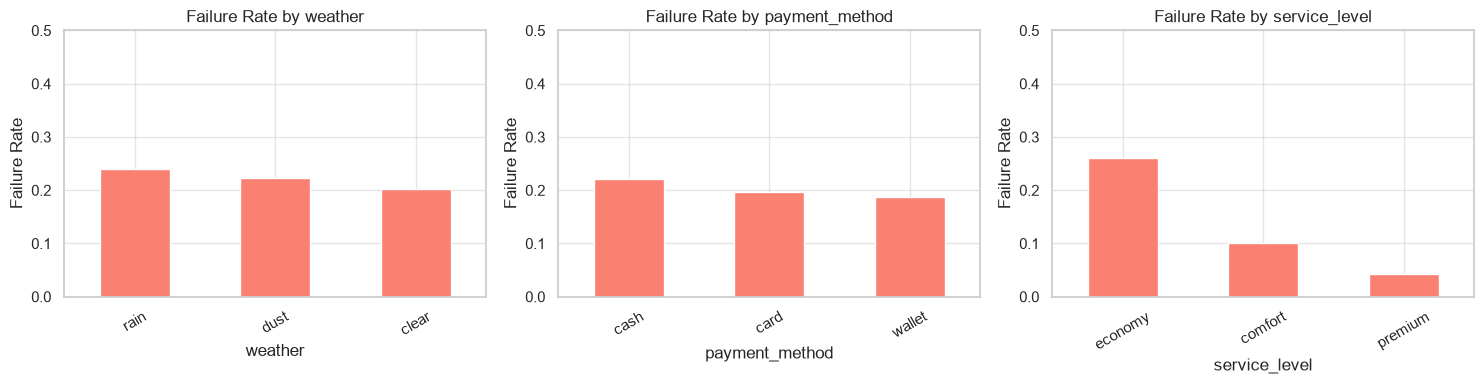

In [108]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cat_features):
    fail_rate = trips.groupby(col)['request_failed'].mean().sort_values(ascending=False)

    fail_rate.plot(
        kind='bar',
        ax=ax,
        color='salmon',
        edgecolor='white'
    )

    ax.set_title(f'Failure Rate by {col}')
    ax.set_ylabel('Failure Rate')
    ax.set_ylim(0, 0.5)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('../reports/figures/failure_rate_by_category.png', dpi=150)
plt.show()


## 8. Temporal Patterns

C:\Users\H P\AppData\Local\Temp\ipykernel_15972\2779959124.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  trips['day_of_week'] = trips['request_ts'].dt.dayofweek  # 0=Mon


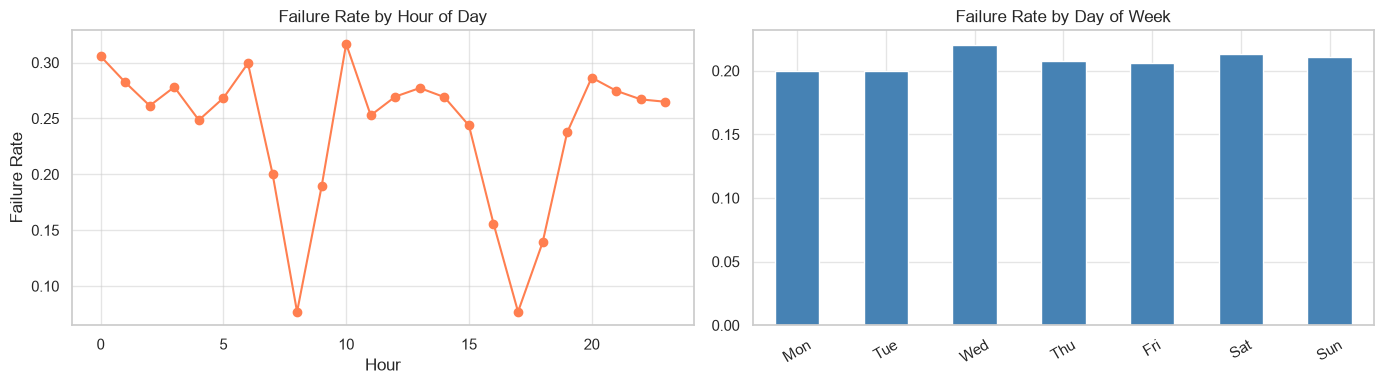

C:\Users\H P\AppData\Local\Temp\ipykernel_15972\2779959124.py:29: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  trips.drop(columns=['hour', 'day_of_week'], inplace=True)


In [109]:

trips['hour'] = trips['request_ts'].dt.hour
trips['day_of_week'] = trips['request_ts'].dt.dayofweek  # 0=Mon

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

trips.groupby('hour')['request_failed'].mean().plot(
    ax=axes[0], marker='o', color='coral'
)
axes[0].set_title('Failure Rate by Hour of Day')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Failure Rate')

day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

fail_by_day = trips.groupby('day_of_week')['request_failed'].mean()
fail_by_day.index = [day_names[i] for i in fail_by_day.index]

fail_by_day.plot(
    kind='bar', ax=axes[1], color='steelblue', edgecolor='white'
)
axes[1].set_title('Failure Rate by Day of Week')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('../reports/figures/temporal_patterns.png', dpi=150)
plt.show()

# Clean up added columns
trips.drop(columns=['hour', 'day_of_week'], inplace=True)


## 9. Other Tables — Quick Look

In [110]:
print('--- CUSTOMERS ---'); print(customers.head(3).to_string()); print(customers.dtypes)
print('\n--- DRIVERS ---'); print(drivers.head(3).to_string()); print(drivers.dtypes)
print('\nDrivers rating_avg missing:', drivers['rating_avg'].isnull().sum(), '(drivers with <min rated trips)')
print('\n--- ZONES ---'); print(zones.to_string())

--- CUSTOMERS ---
   customer_id signup_date  channel   home_zone loyalty_tier
0        20000  2026-02-22      ads   Badr City         gold
1        20001  2026-07-10      ads  Heliopolis       bronze
2        20002  2026-04-13  organic      Agouza       bronze
customer_id              int64
signup_date     datetime64[us]
channel                    str
home_zone                  str
loyalty_tier               str
dtype: object

--- DRIVERS ---
   driver_id  join_date vehicle_type  experience_months   home_zone  rating_avg
0       5000 2026-04-12        sedan                 45  Heliopolis       4.590
1       5001 2026-02-19        sedan                  7       Dokki       4.670
2       5002 2026-06-02        sedan                 50     Zamalek       4.450
driver_id                     int64
join_date            datetime64[us]
vehicle_type                    str
experience_months             int64
home_zone                       str
rating_avg                  float64
dtype: object

D

## 10. Summary — Phase 0 Findings

In [111]:
print('='*60)
print('PHASE 0 — DATASET SUMMARY')
print('='*60)
print(f'Train set (trips.csv):         {len(trips):,} rows')
print(f'Validation (recent_labelled):  {len(recent):,} rows')
print(f'Holdout (holdout_inputs.csv):  {len(holdout):,} rows')
print(f'Customers:  {len(customers):,} | Drivers: {len(drivers):,} | Zones: {len(zones):,}')
print()
print(f'Target: request_failed')
print(f'  0 (completed): {(trips.request_failed==0).sum():,} ({(trips.request_failed==0).mean()*100:.1f}%)')
print(f'  1 (failed):    {(trips.request_failed==1).sum():,} ({(trips.request_failed==1).mean()*100:.1f}%)')
print()
print('Safe features (at_request): 13 columns')
print('LEAKAGE columns (never use): actual_trip_time_min, cancel_reason, driver_arrival_min, support_ticket_flag')
print()
print('Missing values to handle in Phase 1:')
print('  - weather: 1,279 rows (4.5%)')
print('  - drivers.rating_avg: 264 drivers')
print()
print('✓ Phase 0 complete — ready for Phase 1 (Data Audit & Cleaning)')

PHASE 0 — DATASET SUMMARY
Train set (trips.csv):         27,226 rows
Validation (recent_labelled):  3,630 rows
Holdout (holdout_inputs.csv):  2,832 rows
Customers:  6,000 | Drivers: 1,500 | Zones: 24

Target: request_failed
  0 (completed): 21,560 (79.2%)
  1 (failed):    5,666 (20.8%)

Safe features (at_request): 13 columns
LEAKAGE columns (never use): actual_trip_time_min, cancel_reason, driver_arrival_min, support_ticket_flag

Missing values to handle in Phase 1:
  - weather: 1,279 rows (4.5%)
  - drivers.rating_avg: 264 drivers

✓ Phase 0 complete — ready for Phase 1 (Data Audit & Cleaning)
